# Task 05 – Diabetes Prediction (Binary Classification)

**Problem statement:** predict whether a patient is **Diabetic** or **Non-Diabetic** from lab results and basic information,
to support early screening.

**Task type:** supervised **binary classification** – target `Class` (Diabetic / Non-Diabetic).

**Dataset:** Diabetes patients – 10,000 patients, 8 features + target (with missing values).

| Column | Meaning |
|---|---|
| Patient_ID | patient id (no information) |
| Age | age in years |
| Gender | Male / Female |
| Blood_Sugar_Level | blood glucose (mg/dL) |
| Creatinine | kidney function (mg/dL) |
| BMI | body mass index |
| Urea | kidney function (mg/dL) |
| Cholesterol | total cholesterol (mg/dL) |
| HbA1c | average blood sugar over ~3 months (%) |
| **Class** | **target** – Diabetic / Non-Diabetic |

**Metrics:** the classes are imbalanced (≈ 91 % Diabetic), so the main metric is **F1 (macro)** – the average F1 of both classes, so the rare
Non-Diabetic class counts as much as the big one. We also report ROC-AUC, recall of each class, the confusion matrix and the Precision-Recall curves.

This task is also **deployed** as a Gradio app (`app.py`).

# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also hide warnings inside the parallel workers (n_jobs=-1)
%matplotlib inline
sns.set_theme(style='whitegrid')

# Read data

In [2]:
df = pd.read_csv('dataset/diabetes_patients.csv')
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1.0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2.0,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3.0,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4.0,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5.0,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [3]:
df.shape

(10000, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         9689 non-null   float64
 1   Age                9675 non-null   float64
 2   Gender             9530 non-null   object 
 3   Blood_Sugar_Level  9535 non-null   float64
 4   Creatinine         9749 non-null   float64
 5   BMI                9749 non-null   float64
 6   Urea               9740 non-null   float64
 7   Cholesterol        9937 non-null   float64
 8   HbA1c              9986 non-null   float64
 9   Class              9985 non-null   object 
dtypes: float64(8), object(2)
memory usage: 781.4+ KB


In [5]:
df.describe()

,Patient_ID,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,9689.000000,9675.000000,9535.000000,9749.000000,9749.000000,9740.000000,9937.000000,9986.000000
mean,5030.696150,49.971266,169.185632,1.100609,26.746805,35.126591,225.351112,7.503875
std,2920.589701,17.627406,46.055875,0.287080,4.787478,11.818323,43.796330,1.743940
min,1.000000,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,2423.000000,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,5140.000000,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,7562.000000,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,10000.000000,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


# Data Understanding

In [6]:
print(df['Class'].value_counts(dropna=False))
print((df['Class'].value_counts(normalize=True) * 100).round(1))

Class
Diabetic        9131
Non-Diabetic     854
NaN               15
Name: count, dtype: int64
Class
Diabetic        91.4
Non-Diabetic     8.6
Name: proportion, dtype: float64


- Only **8.6 %** of the patients are Non-Diabetic → **imbalanced** data. A model that always says "Diabetic" gets 91 % accuracy but is useless,
  so we use **F1 (macro)** and the recall of the Non-Diabetic class.
- All features are numbers except `Gender`. Every column has some missing values.

# Data Cleaning

In [7]:
df.isnull().sum()

Patient_ID           311
Age                  325
Gender               470
Blood_Sugar_Level    465
Creatinine           251
BMI                  251
Urea                 260
Cholesterol           63
HbA1c                 14
Class                 15
dtype: int64

In [8]:
df.dropna(subset=['Class'], inplace=True)   # the target can't be filled -> drop the 15 rows without a class
df.drop('Patient_ID', axis=1, inplace=True)  # just an id, no information
df.shape

(9985, 9)

In [9]:
missing_per_row = df.drop('Class', axis=1).isnull().sum(axis=1)
print(missing_per_row.value_counts().sort_index())

0    9324
1      18
2      91
3     479
4      17
5      22
6      18
7      16
Name: count, dtype: int64


Most rows have 0 or 1 missing value, but some rows are almost **empty** (5 or more of the 8 features missing) – they are dropped.

In [10]:
df = df[missing_per_row < 5]
print('Number of duplicate rows : ', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
df.shape

Number of duplicate rows :  0


(9929, 9)

- Duplicates are removed **before** the split (otherwise the same patient could be in train and test).
- The remaining missing values (≈ 2 – 5 % per column) are filled **inside the Pipeline**, using the training data only.

# EDA & Statistical Analysis

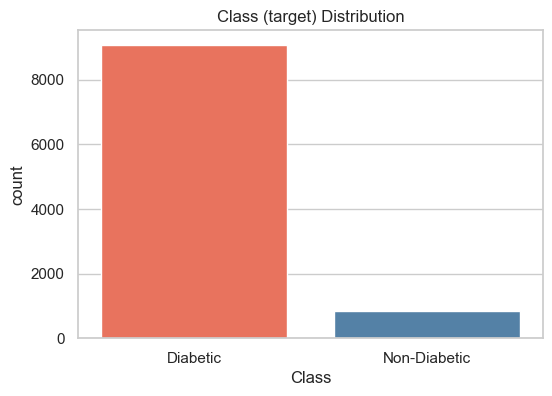

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, palette=['tomato', 'steelblue'])
plt.title('Class (target) Distribution')
plt.show()

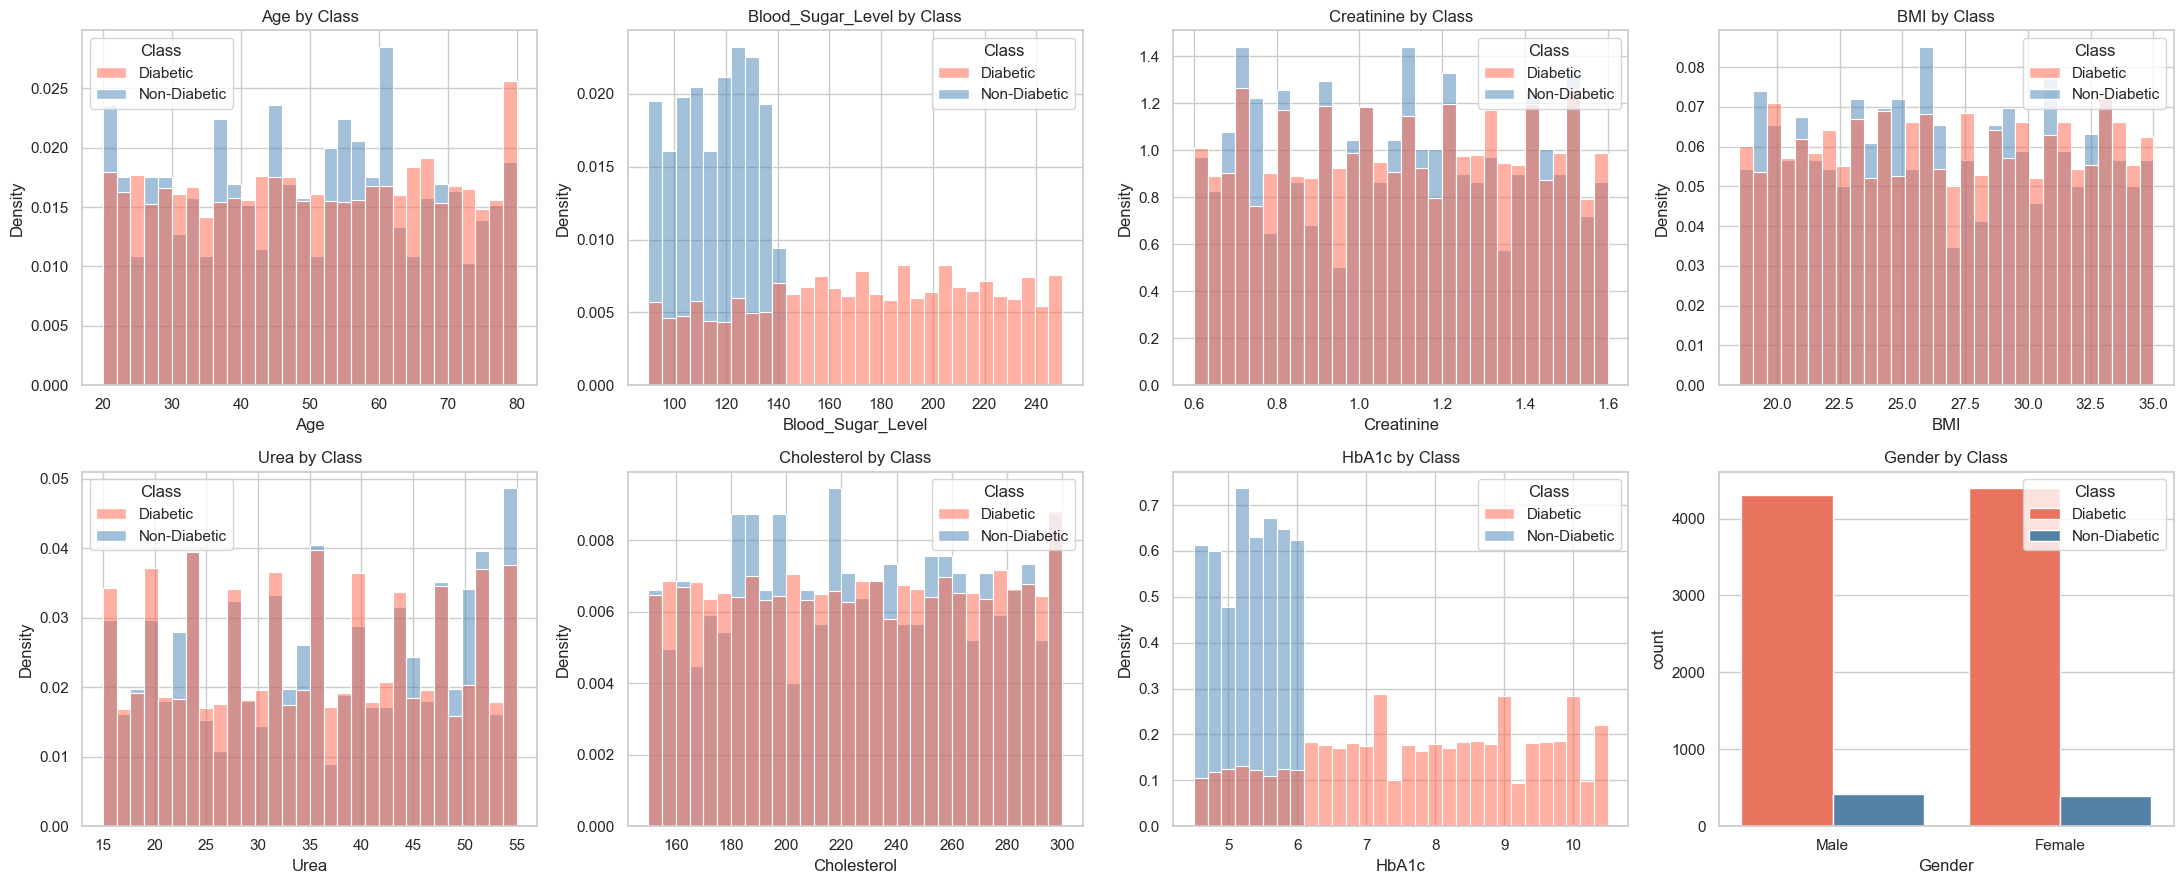

In [12]:
num_features = ['Age', 'Blood_Sugar_Level', 'Creatinine', 'BMI', 'Urea', 'Cholesterol', 'HbA1c']

fig, ax = plt.subplots(2, 4, figsize=(22, 9))
ax = ax.flatten()
for i, col in enumerate(num_features):
    sns.histplot(data=df, x=col, hue='Class', stat='density', common_norm=False, bins=30, ax=ax[i], palette=['tomato', 'steelblue'])
    ax[i].set_title(col + ' by Class')
sns.countplot(x='Gender', hue='Class', data=df, ax=ax[7], palette=['tomato', 'steelblue'])
ax[7].set_title('Gender by Class')
plt.tight_layout()
plt.show()

Only **Blood_Sugar_Level** and **HbA1c** look different between the two classes; the other features have the same distribution in both.

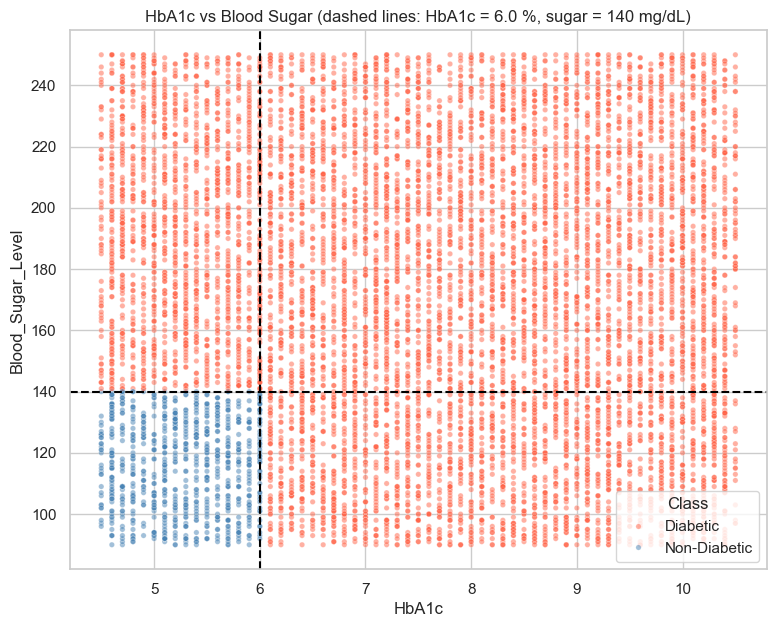

In [13]:
plt.figure(figsize=(9, 7))
sns.scatterplot(x='HbA1c', y='Blood_Sugar_Level', hue='Class', data=df, alpha=0.5, s=15, palette=['tomato', 'steelblue'])
plt.axvline(6.0, color='black', linestyle='--')
plt.axhline(140, color='black', linestyle='--')
plt.title('HbA1c vs Blood Sugar (dashed lines: HbA1c = 6.0 %, sugar = 140 mg/dL)')
plt.show()

**This is the key plot:** all Non-Diabetic patients are inside the box **HbA1c ≤ 6.0 % and Blood Sugar ≤ 140 mg/dL** – the usual medical limits
(sugar < 140 is normal in the glucose tolerance test, HbA1c ≥ 6.0 % is "high risk"). Every patient above one of the two limits is Diabetic.

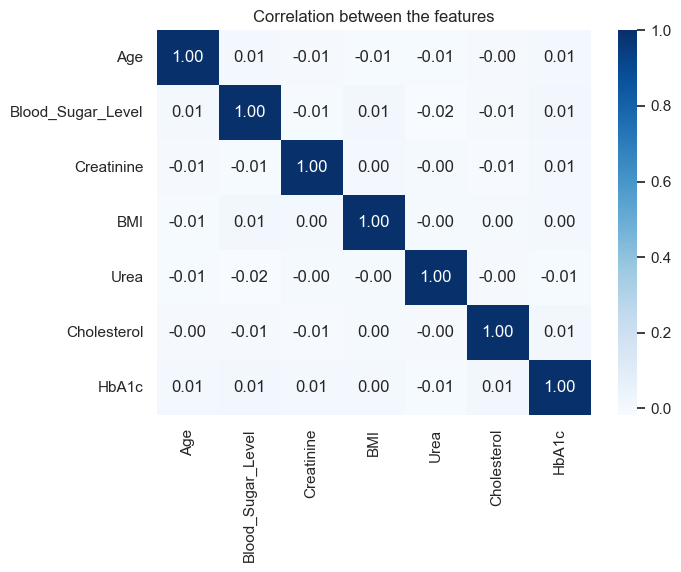

In [14]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_features].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation between the features')
plt.show()

In [15]:
from scipy.stats import ttest_ind, chi2_contingency

print('t-test: is the mean different between Diabetic and Non-Diabetic patients?')
for col in num_features:
    a = df[df['Class'] == 'Diabetic'][col].dropna()
    b = df[df['Class'] == 'Non-Diabetic'][col].dropna()
    print(f'  {col:18s} mean Diabetic = {a.mean():7.2f}   mean Non-Diabetic = {b.mean():7.2f}   p-value = {ttest_ind(a, b).pvalue:.4g}')

print('\nChi-square test: Gender vs Class   p-value =', round(chi2_contingency(pd.crosstab(df['Gender'], df['Class']))[1], 4))

t-test: is the mean different between Diabetic and Non-Diabetic patients?
  Age                mean Diabetic =   50.03   mean Non-Diabetic =   49.22   p-value = 0.2016
  Blood_Sugar_Level  mean Diabetic =  174.18   mean Non-Diabetic =  115.80   p-value = 1.45e-280
  Creatinine         mean Diabetic =    1.10   mean Non-Diabetic =    1.09   p-value = 0.3613
  BMI                mean Diabetic =   26.76   mean Non-Diabetic =   26.62   p-value = 0.4113
  Urea               mean Diabetic =   35.05   mean Non-Diabetic =   35.92   p-value = 0.04161
  Cholesterol        mean Diabetic =  225.34   mean Non-Diabetic =  225.54   p-value = 0.8991
  HbA1c              mean Diabetic =    7.71   mean Non-Diabetic =    5.27   p-value = 0

Chi-square test: Gender vs Class   p-value = 0.3201


**EDA findings**
- **HbA1c** is the strongest sign: mean 7.71 % for Diabetic vs 5.27 % for Non-Diabetic (p ≈ 0).
- **Blood sugar** is the second: 174 vs 116 mg/dL (p ≈ 1e-280).
- **The box rule:** every Non-Diabetic patient has HbA1c ≤ 6.0 % **and** sugar ≤ 140 mg/dL; above either limit, everybody is Diabetic.
  The label follows a clear medical rule, so a very high accuracy is expected.
- **No difference** for Age (p = 0.20), Creatinine (0.36), BMI (0.41), Cholesterol (0.90) and Gender (chi-square p = 0.32).
  Urea has p = 0.04, but the difference is tiny (35.05 vs 35.92) – a chance result, and it is not significant on the training data alone (p = 0.10).
- The features are **not correlated** with each other (all ≈ 0), and their values are spread evenly over normal medical ranges.

# Outliers

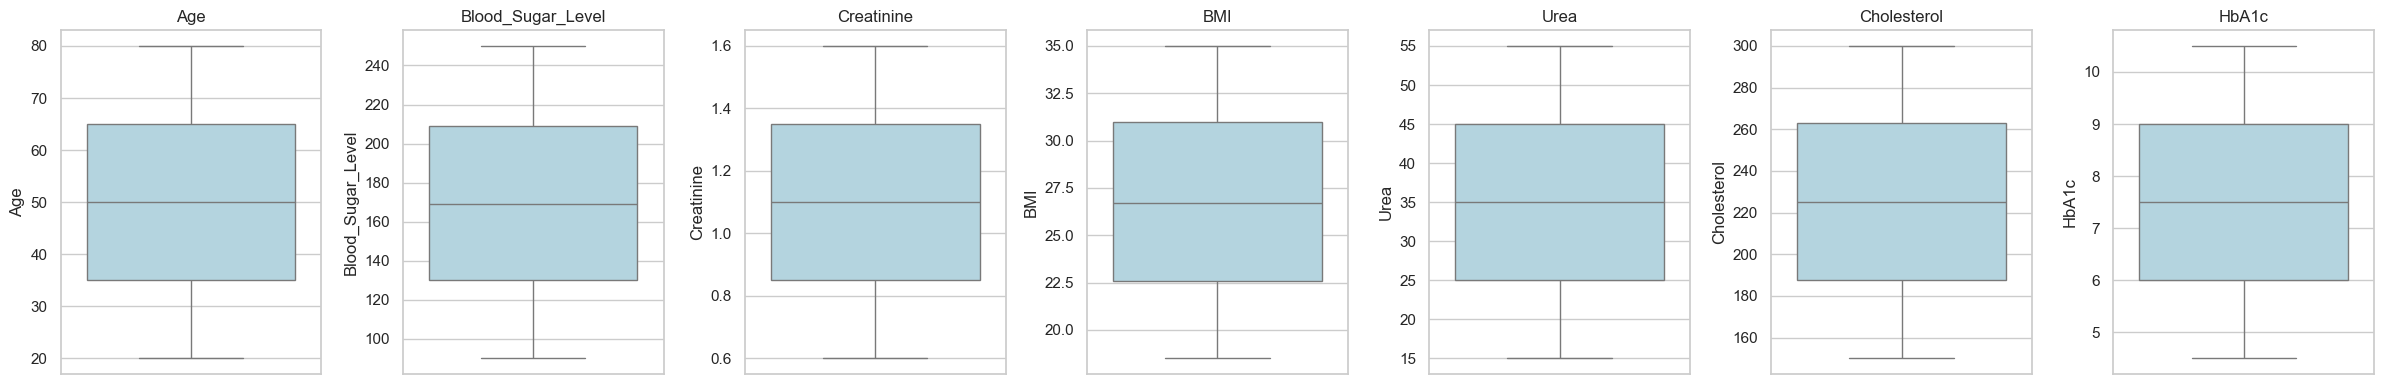

Age                outliers = 0   range = 20.0 to 80.0
Blood_Sugar_Level  outliers = 0   range = 90.0 to 250.0
Creatinine         outliers = 0   range = 0.6 to 1.6
BMI                outliers = 0   range = 18.5 to 35.0
Urea               outliers = 0   range = 15.0 to 55.0
Cholesterol        outliers = 0   range = 150.0 to 300.0
HbA1c              outliers = 0   range = 4.5 to 10.5


In [16]:
fig, ax = plt.subplots(1, 7, figsize=(24, 4))
for i, col in enumerate(num_features):
    sns.boxplot(y=df[col], color='lightblue', ax=ax[i])
    ax[i].set_title(col)
plt.tight_layout()
plt.show()

for col in num_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    print(f'{col:18s} outliers = {((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()}   range = {df[col].min()} to {df[col].max()}')

**No outliers** by the IQR rule – every value is inside a normal medical range, so nothing is removed.

# Feature Engineering

In [17]:
# medical flags (NaN stays NaN, so the imputer can fill it later)
df['High_HbA1c'] = (df['HbA1c'] > 6.0).astype(float)
df.loc[df['HbA1c'].isna(), 'High_HbA1c'] = np.nan

df['High_Sugar'] = (df['Blood_Sugar_Level'] > 140).astype(float)
df.loc[df['Blood_Sugar_Level'].isna(), 'High_Sugar'] = np.nan

pd.crosstab([df['High_HbA1c'], df['High_Sugar']], df['Class'])

Class                  Diabetic  Non-Diabetic
High_HbA1c High_Sugar                        
0.0        0.0                0           816
           1.0             1673             0
1.0        0.0             2254             0
           1.0             4785             0

- `High_HbA1c` (HbA1c > 6.0 %) and `High_Sugar` (sugar > 140 mg/dL) are **medical limits** seen in the scatter plot.
- The table shows that a patient is Non-Diabetic **only** when both flags are 0.
- The flags help simple models: Logistic Regression draws one straight line and can't make the "box" shape by itself, but with the flags it can.
- They are row-by-row rules (no learning from other rows) → **no data leakage**.

# Split data

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = (df['Class'] == 'Diabetic').astype(int)   # 1 = Diabetic, 0 = Non-Diabetic

# stratify=y keeps the same 91 / 9 split in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('X_train = ', X_train.shape, ' Non-Diabetic =', (y_train == 0).sum())
print('X_test  = ', X_test.shape, ' Non-Diabetic =', (y_test == 0).sum())

X_train =  (7943, 10)  Non-Diabetic = 679
X_test  =  (1986, 10)  Non-Diabetic = 170


# Feature Selection (on the training data only)

In [19]:
for col in num_features:
    a = X_train[y_train == 1][col].dropna()
    b = X_train[y_train == 0][col].dropna()
    print(f'{col:18s} p-value = {ttest_ind(a, b).pvalue:.4g}')
print('Gender             p-value =', round(chi2_contingency(pd.crosstab(X_train['Gender'], y_train))[1], 4))

Age                p-value = 0.1827
Blood_Sugar_Level  p-value = 6.211e-220
Creatinine         p-value = 0.6639
BMI                p-value = 0.1965
Urea               p-value = 0.09797
Cholesterol        p-value = 0.3681
HbA1c              p-value = 6.659e-292
Gender             p-value = 0.6765


Only **Blood_Sugar_Level** and **HbA1c** are significant (p < 0.05). Age, Gender, Creatinine, BMI, Urea and Cholesterol are **not** (p > 0.05).
Before dropping them, we check with cross-validation that removing them doesn't hurt:

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def make_preprocessor(num_cols, cat_cols=[]):
    steps = [('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols)]
    if cat_cols:
        steps.append(('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))]), cat_cols))
    return ColumnTransformer(steps)

all_num = num_features + ['High_HbA1c', 'High_Sugar']
selected = ['Blood_Sugar_Level', 'HbA1c', 'High_HbA1c', 'High_Sugar']
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in [('Logistic Regression', LogisticRegression(max_iter=1000)), ('Random Forest', RandomForestClassifier(random_state=42))]:
    all_score = cross_val_score(Pipeline([('preprocessor', make_preprocessor(all_num, ['Gender'])), ('model', model)]), X_train, y_train, cv=kfold, scoring='f1_macro').mean()
    sel_score = cross_val_score(Pipeline([('preprocessor', make_preprocessor(selected)), ('model', model)]), X_train, y_train, cv=kfold, scoring='f1_macro').mean()
    print(f'{name:20s} all features F1 = {all_score:.4f}   selected features F1 = {sel_score:.4f}')

Logistic Regression  all features F1 = 0.9885   selected features F1 = 0.9885


Random Forest        all features F1 = 0.9885   selected features F1 = 0.9878


The selected features give the **same or better** score → we keep only **Blood_Sugar_Level, HbA1c, High_HbA1c and High_Sugar**.
A smaller model is simpler, faster, less likely to learn noise, and the app needs only 2 inputs.

In [21]:
num_cols = selected
X_train = X_train[num_cols]
X_test = X_test[num_cols]

# Imbalanced data: is SMOTE needed?

In [22]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

no_smote = Pipeline([('preprocessor', make_preprocessor(num_cols)), ('model', LogisticRegression(max_iter=1000))])
with_smote = ImbPipeline([('preprocessor', make_preprocessor(num_cols)), ('smote', SMOTE(random_state=42)), ('model', LogisticRegression(max_iter=1000))])

print('Without SMOTE  F1 (macro) =', round(cross_val_score(no_smote, X_train, y_train, cv=kfold, scoring='f1_macro').mean(), 4))
print('With SMOTE     F1 (macro) =', round(cross_val_score(with_smote, X_train, y_train, cv=kfold, scoring='f1_macro').mean(), 4))

Without SMOTE  F1 (macro) = 0.9885
With SMOTE     F1 (macro) = 0.983


**SMOTE makes the model worse here.** The two classes are already clearly separated (the box), so the imbalance is not a problem;
SMOTE only creates synthetic Non-Diabetic points near the border (including points made from median-filled values), which adds wrong patients.
So the imbalance is handled with a **stratified split / stratified CV** and the **F1 (macro)** metric, **without** SMOTE.

# Preprocessing (Pipeline + ColumnTransformer)

In [23]:
preprocessor = make_preprocessor(num_cols)
preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Blood_Sugar_Level', 'HbA1c', 'High_HbA1c',
                                  'High_Sugar'])])

- **Imputation:** median (learned from the training data only). A missing sugar becomes ≈ 169 and its flag becomes 1 – consistent with each other.
- **Scaling:** `StandardScaler` – needed by Logistic Regression, KNN and SVM.
- No categorical columns are left after feature selection, so no encoding is needed.

# Models

| Model | Why it is tried |
|---|---|
| Logistic Regression | simple, explainable baseline for yes/no problems |
| KNN | patients with similar lab results have the same class |
| Decision Tree | can learn the "box" rule directly, easy to read |
| Random Forest / Extra Trees | many trees averaged → more stable |
| SVM | finds the best separating boundary |
| Naive Bayes | very fast probabilistic baseline |
| Gradient Boosting / AdaBoost | each tree fixes the mistakes of the previous ones |
| XGBoost / LightGBM | fast, regularized boosting |

Regression models are **excluded** because the target is a class.

In [24]:
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [25]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(algorithm='SAMME', random_state=42),
    'Extra Trees': ExtraTreesClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
}

## Model comparison with 5-fold stratified cross-validation (training data only)

In [26]:
scoring = {
    'F1 (macro)': 'f1_macro',
    'ROC-AUC': 'roc_auc',
    'Recall Non-Diabetic': make_scorer(recall_score, pos_label=0),
    'Recall Diabetic': 'recall',
    'Accuracy': 'accuracy',
}

results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {'Train F1 (macro)': cv['train_F1 (macro)'].mean()}
    results[name].update({metric: cv['test_' + metric].mean() for metric in scoring})
    print(f"{name:20s} CV F1 (macro) = {results[name]['F1 (macro)']:.4f}")

Logistic Regression  CV F1 (macro) = 0.9885


KNN                  CV F1 (macro) = 0.9862


Decision Tree        CV F1 (macro) = 0.9883


Random Forest        CV F1 (macro) = 0.9878
SVM                  CV F1 (macro) = 0.9885


Naive Bayes          CV F1 (macro) = 0.9184


Gradient Boosting    CV F1 (macro) = 0.9877
AdaBoost             CV F1 (macro) = 0.9885


Extra Trees          CV F1 (macro) = 0.9883
XGBoost              CV F1 (macro) = 0.9882


LightGBM             CV F1 (macro) = 0.9882


In [27]:
comparison = pd.DataFrame(results).T.sort_values('F1 (macro)', ascending=False)
comparison.round(4)

,Train F1 (macro),F1 (macro),ROC-AUC,Recall Non-Diabetic,Recall Diabetic,Accuracy
Logistic Regression,0.9885,0.9885,0.9977,0.9588,1.0000,0.9965
SVM,0.9885,0.9885,0.9987,0.9588,1.0000,0.9965
AdaBoost,0.9885,0.9885,0.9998,0.9588,1.0000,0.9965
Decision Tree,0.9909,0.9883,0.9953,0.9779,0.9981,0.9963
Extra Trees,0.9909,0.9883,0.9953,0.9779,0.9981,0.9963
LightGBM,0.9909,0.9882,0.9999,0.9720,0.9986,0.9963
XGBoost,0.9908,0.9882,0.9999,0.9691,0.9989,0.9963
Random Forest,0.9909,0.9878,0.9976,0.9706,0.9986,0.9962
Gradient Boosting,0.9903,0.9877,0.9999,0.9647,0.9992,0.9962
KNN,0.9895,0.9862,0.9947,0.9691,0.9982,0.9957


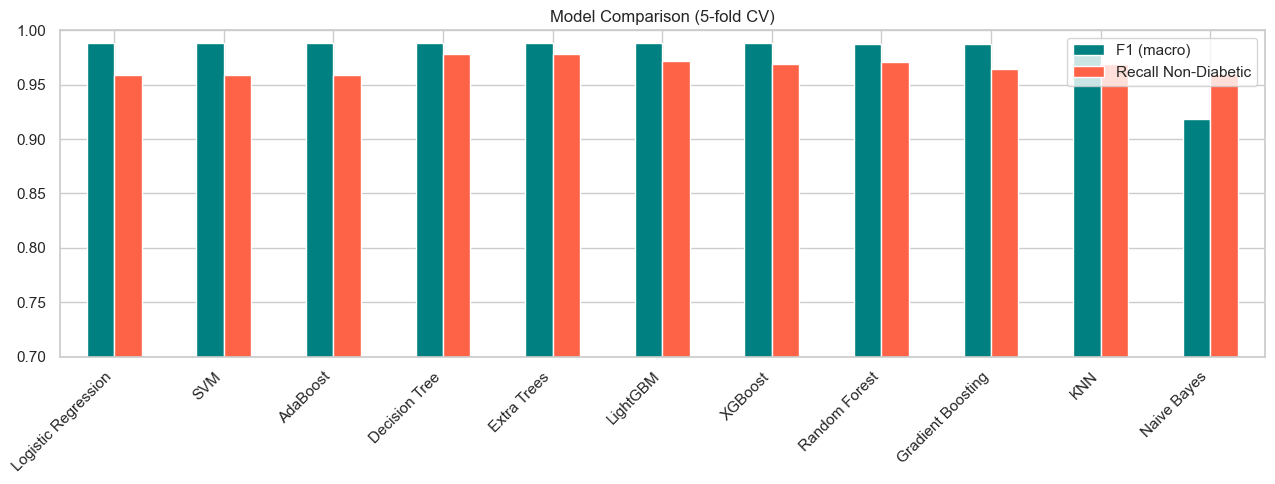

In [28]:
comparison[['F1 (macro)', 'Recall Non-Diabetic']].plot(kind='bar', figsize=(13, 5), color=['teal', 'tomato'])
plt.ylim(0.7, 1.0)
plt.title('Model Comparison (5-fold CV)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comparison results (5-fold stratified CV, training data)**
- **Almost every model is excellent** (CV F1 macro ≈ 0.986 – 0.989, accuracy ≈ 99.6 %): with the two flags, the rule is easy to learn.
- **Logistic Regression, SVM and AdaBoost share the top score (0.9885).** They catch **100 % of the Diabetic** patients and **95.9 %** of the Non-Diabetic ones.
- **Tree models** (Decision Tree, Extra Trees, Random Forest, XGBoost, LightGBM ≈ 0.988) catch a few more Non-Diabetic patients (up to 97.8 %) but make a few more mistakes on Diabetic ones;
  their train score is a little higher than CV (0.991 vs 0.988) → slight overfitting on the median-filled rows.
- **Naive Bayes is clearly the weakest (0.918):** it assumes each feature follows a bell curve, but here the values are spread evenly and the flags are 0/1 – its assumption is wrong.
- **All the remaining mistakes come from missing values** (see the error analysis below) – no model can fix them, which is why all the good models end at the same score.
- The **top 3 (Logistic Regression, SVM, AdaBoost)** are tuned.

# GridSearchCV (top 3 models)

A parameter grid is prepared for every model; the **top 3 models by CV F1 (macro)** are tuned with 5-fold stratified cross-validation on the training data.

In [29]:
param_grids = {
    'Logistic Regression': {'model__C': [0.1, 1, 10, 100]},
    'KNN': {'model__n_neighbors': [3, 5, 11, 21], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [2, 3, 5, None], 'model__min_samples_leaf': [1, 5, 20]},
    'Random Forest': {'model__n_estimators': [100, 300], 'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [1, 5]},
    'SVM': {'model__C': [0.1, 1, 10], 'model__kernel': ['rbf', 'linear']},
    'Naive Bayes': {'model__var_smoothing': [1e-9, 1e-7, 1e-5]},
    'Gradient Boosting': {'model__n_estimators': [50, 100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]},
    'AdaBoost': {'model__n_estimators': [50, 200], 'model__learning_rate': [0.1, 1.0]},
    'Extra Trees': {'model__n_estimators': [100, 300], 'model__max_depth': [3, 5, None], 'model__min_samples_leaf': [1, 5]},
    'XGBoost': {'model__n_estimators': [100, 300], 'model__max_depth': [2, 4, 6], 'model__learning_rate': [0.05, 0.3]},
    'LightGBM': {'model__n_estimators': [100, 300], 'model__num_leaves': [7, 31], 'model__learning_rate': [0.05, 0.1]},
}

In [30]:
top_models = comparison.index[:3]
grids = {}

for name in top_models:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', models[name])])
    grid = GridSearchCV(pipe, param_grids[name], cv=kfold, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[name] = grid

    print('=' * 60)
    print(name)
    print('Parameter grid :', param_grids[name])
    print('best_params_   :', grid.best_params_)
    print('best_score_    :', round(grid.best_score_, 4), '(CV F1 macro)')

Logistic Regression
Parameter grid : {'model__C': [0.1, 1, 10, 100]}
best_params_   : {'model__C': 0.1}
best_score_    : 0.9885 (CV F1 macro)


SVM
Parameter grid : {'model__C': [0.1, 1, 10], 'model__kernel': ['rbf', 'linear']}
best_params_   : {'model__C': 0.1, 'model__kernel': 'rbf'}
best_score_    : 0.9885 (CV F1 macro)


AdaBoost
Parameter grid : {'model__n_estimators': [50, 200], 'model__learning_rate': [0.1, 1.0]}
best_params_   : {'model__learning_rate': 0.1, 'model__n_estimators': 50}
best_score_    : 0.9885 (CV F1 macro)


## Before vs after tuning (cross-validation F1 macro)

In [31]:
tuning = pd.DataFrame({
    'CV F1 before tuning': comparison.loc[top_models, 'F1 (macro)'],
    'CV F1 after tuning': [grids[name].best_score_ for name in top_models],
})
tuning['Improvement'] = tuning['CV F1 after tuning'] - tuning['CV F1 before tuning']
tuning['Best params'] = [grids[name].best_params_ for name in top_models]
tuning = tuning.sort_values('CV F1 after tuning', ascending=False)
tuning

,CV F1 before tuning,CV F1 after tuning,Improvement,Best params
Logistic Regression,0.988474,0.988474,0.0,{'model__C': 0.1}
SVM,0.988474,0.988474,0.0,"{'model__C': 0.1, 'model__kernel': 'rbf'}"
AdaBoost,0.988474,0.988474,0.0,"{'model__learning_rate': 0.1, 'model__n_estima..."


In [32]:
best_name = tuning.index[0]   # chosen by the cross-validation score, not by the test set
best_model = grids[best_name].best_estimator_
print('Best model :', best_name)
print('Best params:', grids[best_name].best_params_)

Best model : Logistic Regression
Best params: {'model__C': 0.1}


# Final Evaluation on the Test Set

The test set is used **only now**, once, for the chosen model.

In [33]:
def classification_metrics(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    return {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision (macro)': precision_score(y, y_pred, average='macro'),
        'Recall (macro)': recall_score(y, y_pred, average='macro'),
        'F1 (macro)': f1_score(y, y_pred, average='macro'),
        'Recall Non-Diabetic': recall_score(y, y_pred, pos_label=0),
        'ROC-AUC': roc_auc_score(y, y_prob),
        'AP Non-Diabetic': average_precision_score(1 - y, 1 - y_prob),
    }

base_model = Pipeline([('preprocessor', preprocessor), ('model', models[best_name])]).fit(X_train, y_train)   # before tuning

final = pd.DataFrame({
    'Before tuning': classification_metrics(base_model, X_test, y_test),
    'After tuning': classification_metrics(best_model, X_test, y_test),
}).T
final.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),Recall Non-Diabetic,ROC-AUC,AP Non-Diabetic
Before tuning,0.9975,0.9986,0.9853,0.9918,0.9706,0.9985,0.9897
After tuning,0.9975,0.9986,0.9853,0.9918,0.9706,0.9984,0.9894


In [34]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]   # probability of Diabetic

print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic'], digits=3))

              precision    recall  f1-score   support

Non-Diabetic      1.000     0.971     0.985       170
    Diabetic      0.997     1.000     0.999      1816

    accuracy                          0.997      1986
   macro avg      0.999     0.985     0.992      1986
weighted avg      0.997     0.997     0.997      1986



## Confusion Matrix

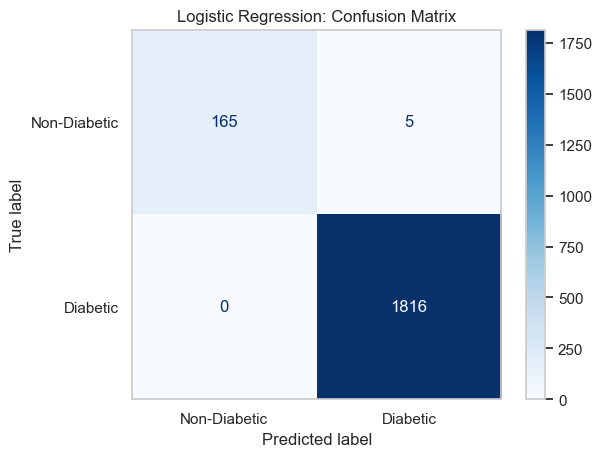

In [35]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Non-Diabetic', 'Diabetic'], cmap='Blues')
plt.title(best_name + ': Confusion Matrix')
plt.grid(False)
plt.show()

## ROC Curve & Precision-Recall Curves

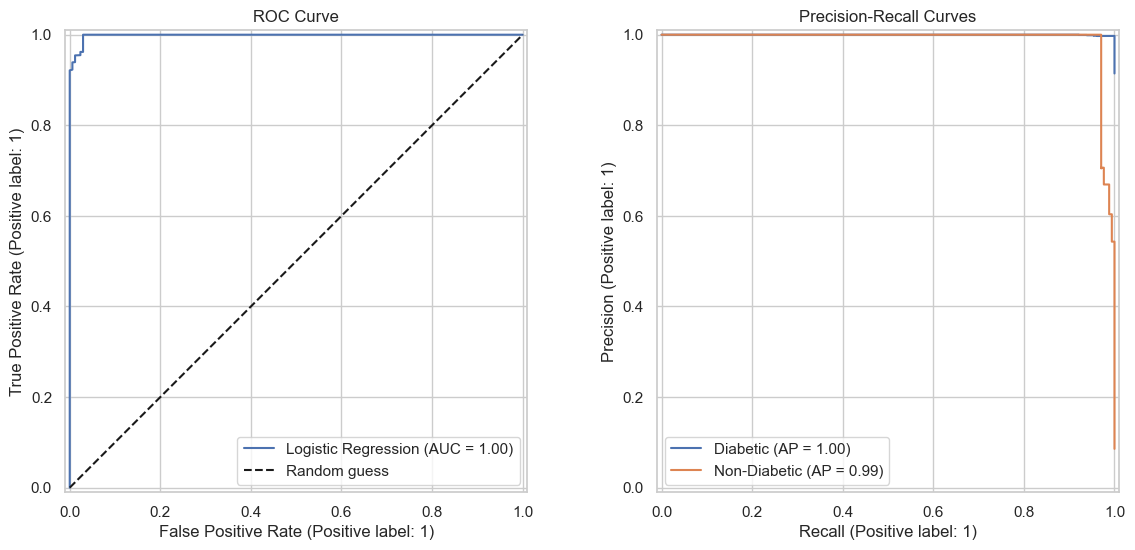

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

RocCurveDisplay.from_predictions(y_test, y_prob, name=best_name, ax=ax[0])
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guess')
ax[0].set_title('ROC Curve')
ax[0].legend()

# Precision-Recall for each class (the rare Non-Diabetic class is the interesting one)
PrecisionRecallDisplay.from_predictions(y_test, y_prob, name='Diabetic', ax=ax[1])
PrecisionRecallDisplay.from_predictions(1 - y_test, 1 - y_prob, name='Non-Diabetic', ax=ax[1])
ax[1].set_title('Precision-Recall Curves')
plt.show()

## Where are the mistakes? (error analysis)

In [37]:
X_test_raw = X.loc[X_test.index]   # the original test rows, before imputation
wrong = y_test != y_pred
key_missing = X_test_raw[['Blood_Sugar_Level', 'HbA1c']].isnull().any(axis=1)

print('Wrong predictions                         :', wrong.sum(), 'of', len(y_test))
print('... of them with sugar or HbA1c missing   :', (wrong & key_missing).sum())
print('Accuracy when sugar & HbA1c are known     :', round(accuracy_score(y_test[~key_missing], y_pred[~key_missing]), 4))
print('Accuracy when one of them is missing      :', round(accuracy_score(y_test[key_missing], y_pred[key_missing]), 4))
X_test_raw[wrong][['Blood_Sugar_Level', 'HbA1c']].assign(Actual=y_test[wrong].map({1: 'Diabetic', 0: 'Non-Diabetic'})).head(10)

Wrong predictions                         : 5 of 1986
... of them with sugar or HbA1c missing   : 5
Accuracy when sugar & HbA1c are known     : 1.0
Accuracy when one of them is missing      : 0.9359


,Blood_Sugar_Level,HbA1c,Actual
3717,NaN,5.9,Non-Diabetic
3519,NaN,5.6,Non-Diabetic
3455,NaN,5.1,Non-Diabetic
3752,NaN,5.3,Non-Diabetic
3775,NaN,5.3,Non-Diabetic


## Which features matter? & the rule learned by a small tree

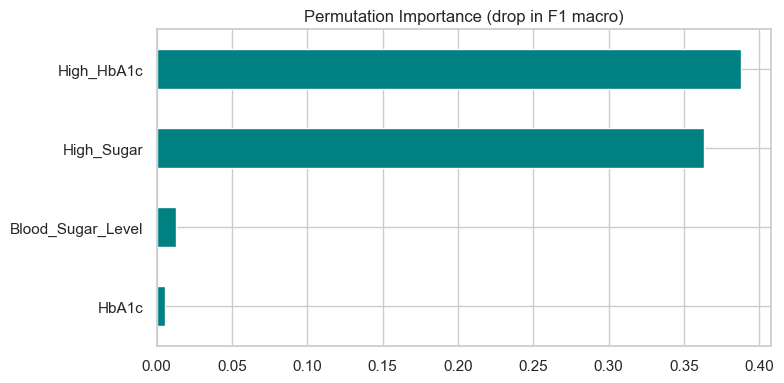

In [38]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring='f1_macro', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance (drop in F1 macro)')
plt.tight_layout()
plt.show()

In [39]:
# a depth-2 tree on the training data: it finds the medical rule by itself
small_tree = Pipeline([('imputer', SimpleImputer(strategy='median')), ('tree', DecisionTreeClassifier(max_depth=2, random_state=42))])
small_tree.fit(X_train[['Blood_Sugar_Level', 'HbA1c']], y_train)
print(export_text(small_tree.named_steps['tree'], feature_names=['Blood_Sugar_Level', 'HbA1c'], class_names=['Non-Diabetic', 'Diabetic']))

|--- HbA1c <= 6.05
|   |--- Blood_Sugar_Level <= 140.50
|   |   |--- class: Non-Diabetic
|   |--- Blood_Sugar_Level >  140.50
|   |   |--- class: Diabetic
|--- HbA1c >  6.05
|   |--- class: Diabetic



**Interpretation of results**
- **GridSearchCV:** all three models stay at **0.9885** – the data is already perfectly separated except for the rows with missing values, so there is nothing left to tune.
  Ties are broken by the table order, and **Logistic Regression (C = 0.1)** is chosen: the simplest and easiest model to explain.
- **Test set:** accuracy **99.75 %**, F1 (macro) **0.992**, ROC-AUC **0.998**, AP (Non-Diabetic) 0.989. Before vs after tuning is identical.
- **Classification report:** Diabetic recall **1.000** (no diabetic patient is missed) and precision 0.997; Non-Diabetic recall 0.971 (165 of 170) with precision 1.000.
- **Confusion matrix:** only **5 mistakes out of 1,986** – all of them are Non-Diabetic patients predicted as Diabetic.
- **Error analysis:** all 5 mistakes have a **missing blood sugar** value. The median (≈ 169) is filled in, so the model thinks the sugar is high.
  When both sugar and HbA1c are known, the model is **100 % correct**; when one is missing it is 93.6 %.
  For a patient with normal HbA1c and an unknown sugar, the right answer simply can't be known → in practice the doctor should **order the missing test**.
- **For screening this is the safe direction:** the model never misses a diabetic patient; its only errors are false alarms that a sugar test would clear.
- **ROC / PR curves** are almost perfect for both classes; the PR curve of the rare Non-Diabetic class (AP 0.989) confirms it is detected well, not hidden by the 91 % majority.
- **Feature importance:** the model relies almost only on the two engineered flags (shuffling **High_HbA1c** drops F1 by ≈ 0.39, **High_Sugar** by ≈ 0.36);
  the raw values add very little → the **feature engineering** is what lets a simple linear model learn the "box" rule.
- A depth-2 Decision Tree trained on the training data **finds the same rule by itself**: HbA1c ≤ 6.05 and sugar ≤ 140.5 → Non-Diabetic.

# Save the model (for the Gradio app)

In [40]:
import joblib

joblib.dump(best_model, 'models/diabetes_model.pkl')

loaded_model = joblib.load('models/diabetes_model.pkl')
new_patients = pd.DataFrame({'Blood_Sugar_Level': [120, 180, 130], 'HbA1c': [5.4, 5.5, 7.2]})
new_patients['High_HbA1c'] = (new_patients['HbA1c'] > 6.0).astype(float)          # same feature engineering as above
new_patients['High_Sugar'] = (new_patients['Blood_Sugar_Level'] > 140).astype(float)

new_patients['Prediction'] = np.where(loaded_model.predict(new_patients[num_cols]) == 1, 'Diabetic', 'Non-Diabetic')
new_patients['P(Diabetic)'] = loaded_model.predict_proba(new_patients[num_cols])[:, 1].round(3)
new_patients

,Blood_Sugar_Level,HbA1c,High_HbA1c,High_Sugar,Prediction,P(Diabetic)
0,120,5.4,0.0,0.0,Non-Diabetic,0.040
1,180,5.5,0.0,1.0,Diabetic,0.976
2,130,7.2,1.0,0.0,Diabetic,0.993


# Conclusions & Recommendations

**Conclusions**
1. After removing 15 rows without a class and 56 almost-empty rows, **9,929 patients** were used; the other missing values were imputed inside the pipeline.
2. The diagnosis follows a **medical rule**: Diabetic if **HbA1c > 6.0 %** or **blood sugar > 140 mg/dL**. Age, gender, BMI, creatinine, urea and cholesterol carry no information
   and were removed by feature selection (checked with CV on the training data).
3. SMOTE was tested and made the model **worse**, so the imbalance (91 / 9) was handled with stratified splitting and the macro F1 metric.
4. 11 classification models were compared; the best, **Logistic Regression (C = 0.1)**, reaches **99.75 % accuracy, F1 (macro) 0.992 and ROC-AUC 0.998** on the test set,
   misses **no** diabetic patient, and is **100 % correct whenever both lab values are known**.
5. The pipeline is saved and deployed as a **Gradio app** that needs only HbA1c and blood sugar.

**Recommendations**
- Always measure **both HbA1c and blood sugar** – every remaining error came from a missing sugar value.
- Use the model as a **screening aid**, not a diagnosis; borderline values near 6.0 % / 140 mg/dL should be confirmed by a doctor.
- The data looks generated from a clear rule (even spread of values, no correlations). On real hospital data, expect lower accuracy and re-check which features matter (age, BMI and family history usually do).